# InkSight: Handwritten Character Recognition

**Project type:** Classifier (each image belongs to exactly one of 47 discrete classes; nothing continuous is predicted).

## Problem Statement

- **Input:** a single grayscale image of one handwritten character, 28 x 28 pixels.
- **Output:** one of 47 classes: the digits 0 to 9, the uppercase letters A to Z, and the 11 lowercase letters whose shape differs from their uppercase form (a, b, d, e, f, g, h, n, q, r, t).
- **Core challenge:** handwriting varies enormously between people, and several characters look nearly identical when handwritten (O and 0, I, l and 1, S and 5, Z and 2). The model must learn shape features that hold up across thousands of writing styles, then work on brand-new drawings made live in a web app.

**Dataset:** EMNIST Balanced, loaded directly from `torchvision.datasets.EMNIST`. It contains 131,600 images (112,800 for training, 18,800 for testing) with the same number of samples for every class.

> Runtime setting: in Colab choose **Runtime > Change runtime type > T4 GPU** before running.

In [20]:
# this downloads the project code (model and web app) and moves into its folder
![ -d inksight ] || git clone -q https://github.com/ff7nucleus/inksight.git
%cd inksight
!pip install -q gradio

/content/inksight/inksight


In [21]:
# this imports every library used in the notebook
import time, os, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from PIL import Image, ImageOps
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from model import InkNet, prepare

# this fixes the random seed so results can be reproduced
torch.manual_seed(42)
np.random.seed(42)

# this uses the gpu when available and falls back to cpu
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

Device: cuda


## 1. Data Pipeline

EMNIST stores every image transposed (rotated and mirrored), so each image is flipped upright before use. Training images also receive small random rotations, shifts and zooms (data augmentation) so the model learns to handle the natural wobble of real handwriting. Validation and test images are never augmented.

In [22]:
# this flips emnist images upright (the raw files are stored transposed)
def upright(img):
    return img.transpose(Image.Transpose.TRANSPOSE)

# this is the training transform: upright, random wobble, tensor, normalize
train_tf = transforms.Compose([
    transforms.Lambda(upright),
    transforms.RandomAffine(degrees=10, translate=(0.1, 0.1), scale=(0.9, 1.1)),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,)),
])

# this is the evaluation transform: same steps without the random wobble
eval_tf = transforms.Compose([
    transforms.Lambda(upright),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,)),
])

# this downloads emnist balanced from torchvision
train_aug = datasets.EMNIST("data", split="balanced", train=True, download=True, transform=train_tf)
train_plain = datasets.EMNIST("data", split="balanced", train=True, download=True, transform=eval_tf)
test_set = datasets.EMNIST("data", split="balanced", train=False, download=True, transform=eval_tf)
classes = train_aug.classes
print(f"Classes ({len(classes)}):", " ".join(classes))

100%|██████████| 562M/562M [00:04<00:00, 122MB/s]


Classes (47): 0 1 2 3 4 5 6 7 8 9 A B C D E F G H I J K L M N O P Q R S T U V W X Y Z a b d e f g h n q r t


In [23]:
# this holds out 10% of the training images as a validation set for early stopping
idx = torch.randperm(len(train_aug))
cut = int(0.9 * len(idx))
train_set = Subset(train_aug, idx[:cut])
val_set = Subset(train_plain, idx[cut:])

# this builds the data loaders: batching, shuffling for training, parallel loading
loader_args = dict(batch_size=128, num_workers=2, pin_memory=True)
train_loader = DataLoader(train_set, shuffle=True, **loader_args)
val_loader = DataLoader(val_set, shuffle=False, **loader_args)
test_loader = DataLoader(test_set, shuffle=False, **loader_args)

print(f"Train: {len(train_set):,} | Validation: {len(val_set):,} | Test: {len(test_set):,}")

Train: 101,520 | Validation: 11,280 | Test: 18,800


## 2. Exploring the Data

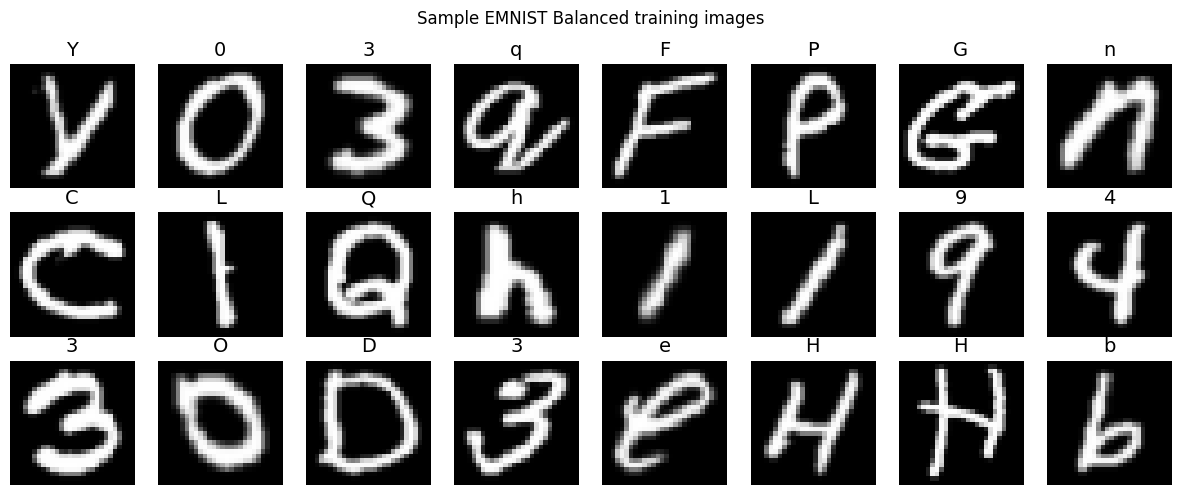

In [24]:
# this shows 24 training images with their labels to confirm they load upright
raw = datasets.EMNIST("data", split="balanced", train=True, download=True, transform=transforms.Lambda(upright))
fig, axes = plt.subplots(3, 8, figsize=(12, 5))
for ax, i in zip(axes.flat, torch.randint(len(raw), (24,)).tolist()):
    img, label = raw[i]
    ax.imshow(img, cmap="gray")
    ax.set_title(classes[label], fontsize=14)
    ax.axis("off")
plt.suptitle("Sample EMNIST Balanced training images")
plt.tight_layout()
plt.show()

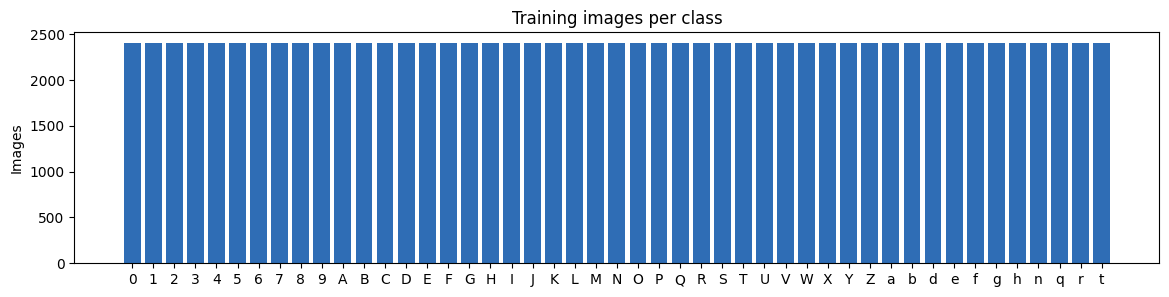

Min per class: 2,400 | Max per class: 2,400


In [25]:
# this counts images per class to confirm the dataset is balanced
counts = np.bincount(raw.targets.numpy(), minlength=len(classes))
plt.figure(figsize=(14, 3))
plt.bar(classes, counts, color="#2f6db5")
plt.title("Training images per class")
plt.ylabel("Images")
plt.show()
print(f"Min per class: {counts.min():,} | Max per class: {counts.max():,}")

## 3. Models

Two networks are trained and compared:

- **Baseline (MLP):** a simple 2-layer fully connected network. It treats the image as a flat list of 784 pixels, so it has no sense of where strokes sit relative to each other.
- **InkNet (CNN):** a convolutional network with four convolution layers and two fully connected layers. Convolutions scan the image with small filters, which is why they excel at images: they detect the same stroke or curve anywhere it appears. Batch normalization stabilizes training and dropout reduces overfitting.

**Loss function:** Cross-Entropy Loss, the standard choice for single-label multi-class classification. It measures how much probability the model assigns to the correct character and penalizes confident wrong answers most heavily.

**Optimizer:** Adam (learning rate 0.001). It adapts the step size for every weight automatically, which makes it converge quickly and reliably without manual tuning.

**Overfitting controls:** learning rate scheduling (the rate is halved when validation loss stops improving) and early stopping (training ends after 3 epochs with no improvement, and the best weights are restored).

In [26]:
# this is the baseline: a 2-layer fully connected network with no spatial awareness
baseline = nn.Sequential(
    nn.Flatten(),
    nn.Linear(28 * 28, 256), nn.ReLU(),
    nn.Linear(256, len(classes)),
).to(device)

# this is the main model, defined in model.py and shared with the web app
inknet = InkNet(len(classes)).to(device)

# this prints each model's size and the full cnn architecture
count = lambda m: sum(p.numel() for p in m.parameters())
print(f"Baseline parameters: {count(baseline):,}")
print(f"InkNet parameters:   {count(inknet):,}")
print(inknet)

Baseline parameters: 213,039
InkNet parameters:   880,527
InkNet(
  (block1): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Dropout(p=0.25, inplace=False)
  )
  (block2): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, strid

## 4. Training

In [27]:
# this runs one full pass over a data loader, training or evaluating
def run_epoch(model, loader, loss_fn, optimizer=None):
    model.train(optimizer is not None)
    total_loss, correct, preds, labels = 0.0, 0, [], []
    with torch.set_grad_enabled(optimizer is not None):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = loss_fn(out, y)

            # this updates the weights (training only)
            if optimizer:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            # this tracks loss, accuracy and predictions
            total_loss += loss.item() * len(y)
            correct += (out.argmax(1) == y).sum().item()
            preds.append(out.argmax(1).cpu())
            labels.append(y.cpu())
    n = len(loader.dataset)
    return total_loss / n, correct / n, torch.cat(preds), torch.cat(labels)


# this trains a model with lr scheduling and early stopping, keeping the best weights
def fit(model, max_epochs, patience=3):
    loss_fn = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, factor=0.5, patience=1)
    history, best_loss, best_state, wait = [], float("inf"), None, 0

    for epoch in range(1, max_epochs + 1):
        start = time.time()
        tr_loss, tr_acc, _, _ = run_epoch(model, train_loader, loss_fn, optimizer)
        va_loss, va_acc, _, _ = run_epoch(model, val_loader, loss_fn)
        scheduler.step(va_loss)
        history.append(dict(epoch=epoch, train_loss=tr_loss, val_loss=va_loss, train_acc=tr_acc, val_acc=va_acc))
        print(f"Epoch {epoch:2d} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
              f"val loss {va_loss:.4f} acc {va_acc:.4f} | lr {optimizer.param_groups[0]['lr']:.6f} | {time.time() - start:.0f}s")

        # this saves the best weights and stops when validation loss stops improving
        if va_loss < best_loss:
            best_loss, best_state, wait = va_loss, copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if wait >= patience:
                print(f"Early stopping: no improvement for {patience} epochs.")
                break

    model.load_state_dict(best_state)
    return pd.DataFrame(history)

In [28]:
# this trains the baseline for comparison
print("Training baseline MLP")
base_hist = fit(baseline, max_epochs=8)

Training baseline MLP
Epoch  1 | train loss 1.9795 acc 0.4623 | val loss 1.0070 acc 0.7165 | lr 0.001000 | 20s
Epoch  2 | train loss 1.1851 acc 0.6550 | val loss 0.7781 acc 0.7618 | lr 0.001000 | 20s
Epoch  3 | train loss 0.9919 acc 0.7020 | val loss 0.6799 acc 0.7918 | lr 0.001000 | 19s
Epoch  4 | train loss 0.8993 acc 0.7268 | val loss 0.6417 acc 0.7974 | lr 0.001000 | 20s
Epoch  5 | train loss 0.8447 acc 0.7401 | val loss 0.6181 acc 0.8008 | lr 0.001000 | 20s
Epoch  6 | train loss 0.8135 acc 0.7485 | val loss 0.5855 acc 0.8105 | lr 0.001000 | 19s
Epoch  7 | train loss 0.7890 acc 0.7528 | val loss 0.5645 acc 0.8177 | lr 0.001000 | 19s
Epoch  8 | train loss 0.7648 acc 0.7602 | val loss 0.5504 acc 0.8229 | lr 0.001000 | 20s


In [29]:
# this trains the main cnn
print("Training InkNet CNN")
ink_hist = fit(inknet, max_epochs=25)

Training InkNet CNN
Epoch  1 | train loss 1.4807 acc 0.5543 | val loss 0.4893 acc 0.8309 | lr 0.001000 | 20s
Epoch  2 | train loss 0.8977 acc 0.7060 | val loss 0.4288 acc 0.8538 | lr 0.001000 | 19s
Epoch  3 | train loss 0.7969 acc 0.7365 | val loss 0.4049 acc 0.8605 | lr 0.001000 | 19s
Epoch  4 | train loss 0.7421 acc 0.7520 | val loss 0.3891 acc 0.8695 | lr 0.001000 | 20s
Epoch  5 | train loss 0.7037 acc 0.7667 | val loss 0.3740 acc 0.8735 | lr 0.001000 | 20s
Epoch  6 | train loss 0.6763 acc 0.7729 | val loss 0.3732 acc 0.8686 | lr 0.001000 | 20s
Epoch  7 | train loss 0.6496 acc 0.7833 | val loss 0.3568 acc 0.8775 | lr 0.001000 | 20s
Epoch  8 | train loss 0.6309 acc 0.7894 | val loss 0.3486 acc 0.8837 | lr 0.001000 | 20s
Epoch  9 | train loss 0.6117 acc 0.7956 | val loss 0.3424 acc 0.8836 | lr 0.001000 | 19s
Epoch 10 | train loss 0.5936 acc 0.8015 | val loss 0.3496 acc 0.8767 | lr 0.001000 | 19s
Epoch 11 | train loss 0.5799 acc 0.8067 | val loss 0.3425 acc 0.8846 | lr 0.000500 | 20s
E

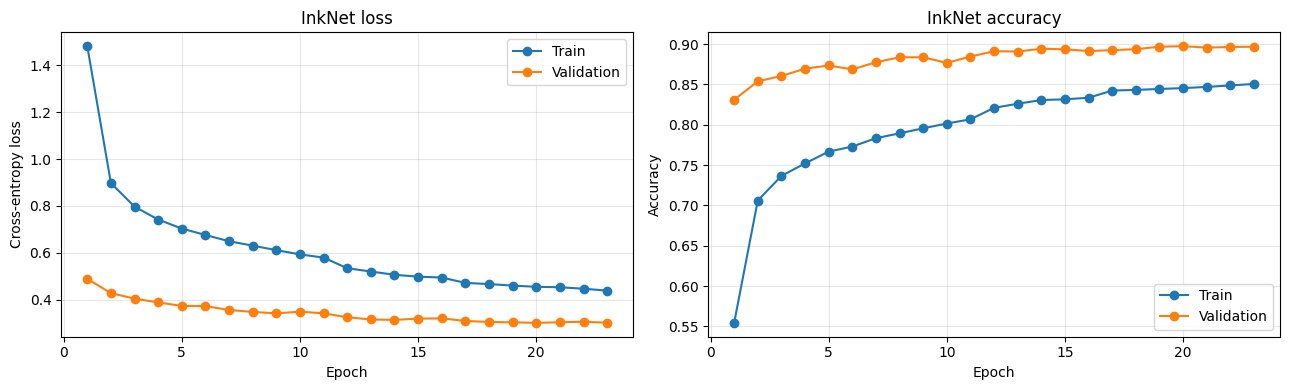

In [30]:
# this plots training versus validation loss and accuracy for the cnn
os.makedirs("figures", exist_ok=True)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
ax1.plot(ink_hist.epoch, ink_hist.train_loss, "o-", label="Train")
ax1.plot(ink_hist.epoch, ink_hist.val_loss, "o-", label="Validation")
ax1.set(title="InkNet loss", xlabel="Epoch", ylabel="Cross-entropy loss")
ax2.plot(ink_hist.epoch, ink_hist.train_acc, "o-", label="Train")
ax2.plot(ink_hist.epoch, ink_hist.val_acc, "o-", label="Validation")
ax2.set(title="InkNet accuracy", xlabel="Epoch", ylabel="Accuracy")
for ax in (ax1, ax2):
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("figures/training_curves.png", dpi=150)
plt.show()

## 5. Evaluation on the Unseen Test Set

In [31]:
# this scores both models on the 18,800 test images neither model has seen
loss_fn = nn.CrossEntropyLoss()
results = []
for name, m in [("Baseline MLP", baseline), ("InkNet CNN", inknet)]:
    _, acc, preds, labels = run_epoch(m, test_loader, loss_fn)
    results.append({"Model": name, "Parameters": f"{count(m):,}", "Accuracy": round(acc, 4),
                    "Macro F1": round(f1_score(labels, preds, average="macro"), 4)})
    if name == "InkNet CNN":
        ink_preds, ink_labels = preds, labels
pd.DataFrame(results)

,Model,Parameters,Accuracy,Macro F1
0,Baseline MLP,"213,039",0.8241,0.8208
1,InkNet CNN,"880,527",0.8894,0.8879


In [32]:
# this prints precision, recall and f1 for every character
print(classification_report(ink_labels, ink_preds, target_names=classes, digits=3))

              precision    recall  f1-score   support

           0      0.645     0.777     0.705       400
           1      0.508     0.760     0.609       400
           2      0.929     0.880     0.904       400
           3      0.992     0.983     0.987       400
           4      0.951     0.930     0.941       400
           5      0.955     0.892     0.922       400
           6      0.931     0.945     0.938       400
           7      0.973     0.990     0.981       400
           8      0.931     0.975     0.952       400
           9      0.650     0.877     0.747       400
           A      0.975     0.988     0.981       400
           B      0.963     0.970     0.966       400
           C      0.958     0.973     0.965       400
           D      0.946     0.915     0.930       400
           E      0.980     0.985     0.983       400
           F      0.696     0.578     0.631       400
           G      0.936     0.958     0.947       400
           H      0.968    

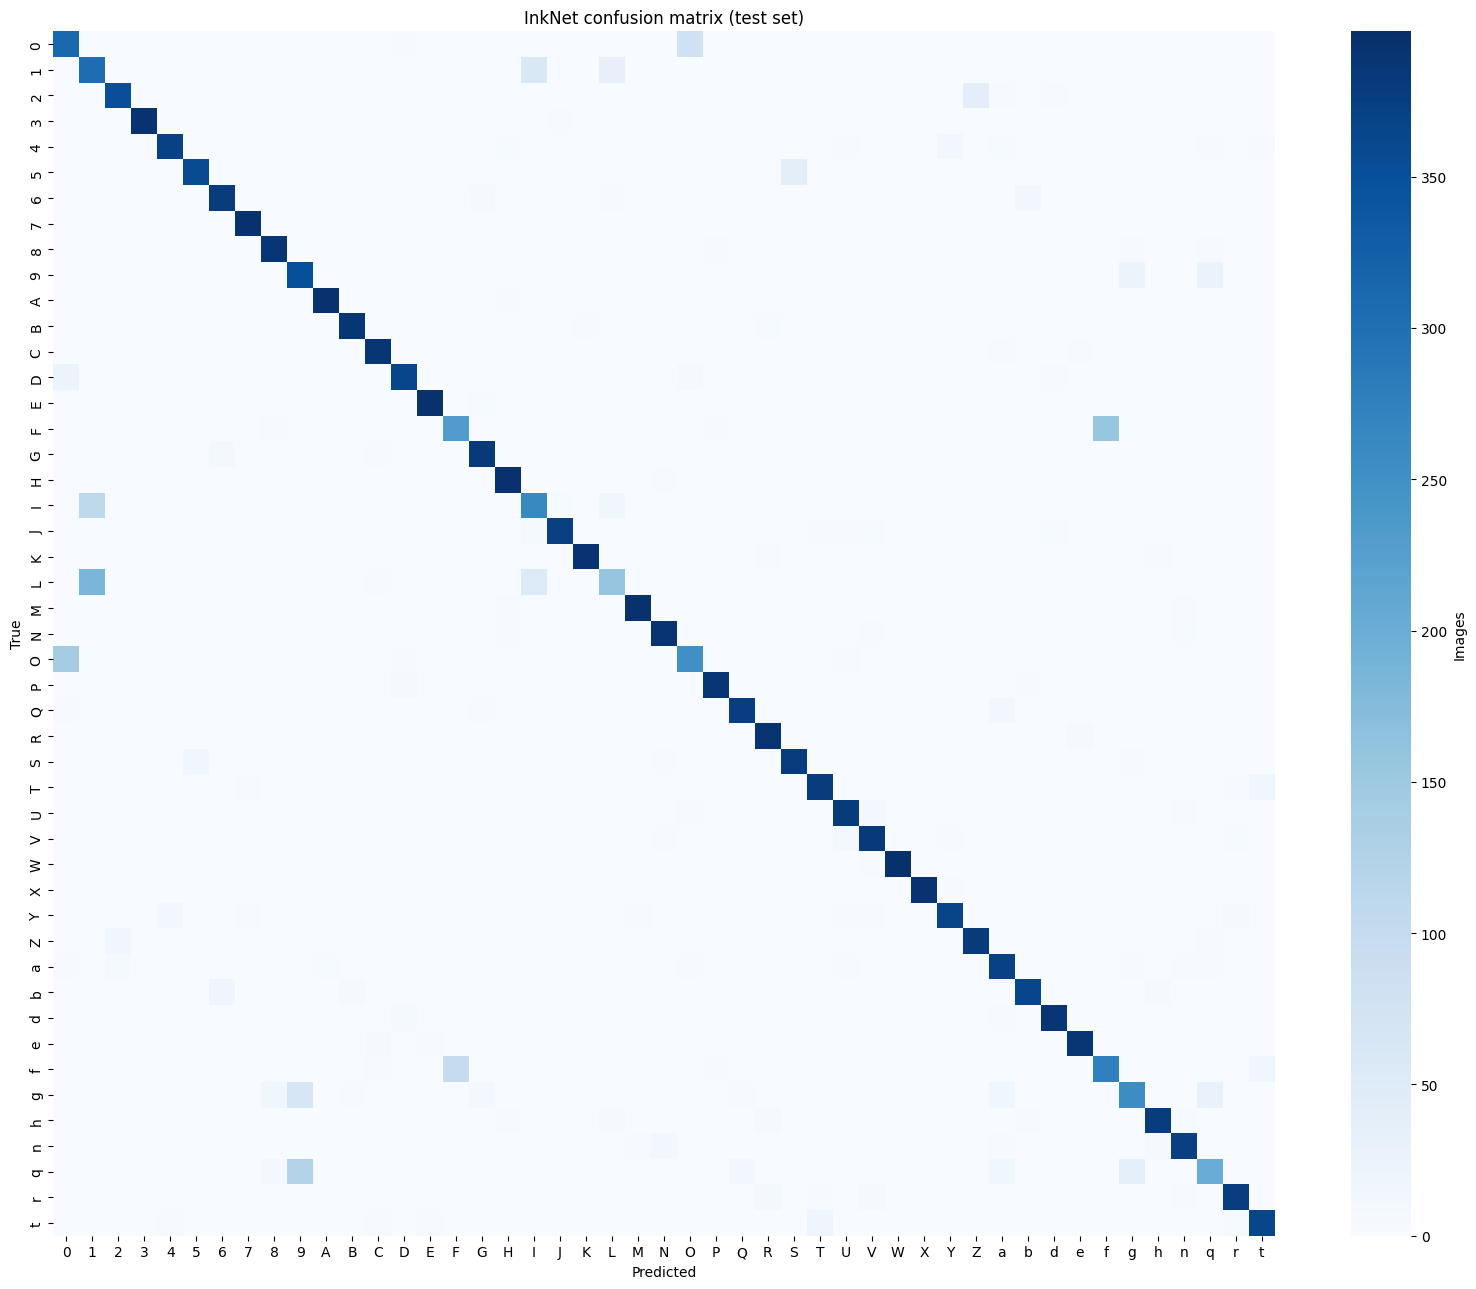

In [33]:
# this draws the confusion matrix: rows are true characters, columns are predictions
cm = confusion_matrix(ink_labels, ink_preds)
plt.figure(figsize=(16, 13))
sns.heatmap(cm, xticklabels=classes, yticklabels=classes, cmap="Blues", cbar_kws={"label": "Images"})
plt.title("InkNet confusion matrix (test set)")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.tight_layout()
plt.savefig("figures/confusion_matrix.png", dpi=150)
plt.show()

In [34]:
# this lists the 10 character pairs the model mixes up most often
off = cm.copy()
np.fill_diagonal(off, 0)
pairs = [(classes[i], classes[j], off[i, j]) for i, j in zip(*np.unravel_index(np.argsort(off, axis=None)[::-1][:10], off.shape))]
pd.DataFrame(pairs, columns=["True", "Predicted as", "Times"])

,True,Predicted as,Times
0,L,1,184
1,F,f,157
2,O,0,143
3,q,9,124
4,I,1,110
5,f,F,100
6,0,O,82
7,g,9,64
8,1,I,60
9,L,I,52


## 6. Inference Timer

In [35]:
# this saves the trained weights and class list used by the web app
torch.save(inknet.state_dict(), "inksight_cnn.pth")
with open("class_names.txt", "w") as f:
    f.write("\n".join(classes))

# this saves 8 test characters as ink-on-paper sample images for the app
os.makedirs("examples", exist_ok=True)
raw_test = datasets.EMNIST("data", split="balanced", train=False, download=True, transform=transforms.Lambda(upright))
for k, i in enumerate(torch.randint(len(raw_test), (8,)).tolist()):
    img, label = raw_test[i]
    ImageOps.invert(img).resize((280, 280), Image.LANCZOS).save(f"examples/sample_{k + 1}.png")
print("Saved inksight_cnn.pth, class_names.txt and examples/")

Saved inksight_cnn.pth, class_names.txt and examples/


In [36]:
# this reloads the saved model on cpu, exactly as the web app does
cpu_model = InkNet(len(classes))
cpu_model.load_state_dict(torch.load("inksight_cnn.pth", map_location="cpu"))
cpu_model.eval()
to_tensor = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])

# this times one full prediction: preprocessing plus the forward pass
img = Image.open("examples/sample_1.png")
start = time.perf_counter()
with torch.inference_mode():
    pred = cpu_model(to_tensor(prepare(img)).unsqueeze(0)).argmax(1).item()
elapsed = time.perf_counter() - start
print(f"Predicted '{classes[pred]}' in {elapsed:.4f} seconds")

# this averages 100 runs for a stable typical speed
times = []
for _ in range(100):
    start = time.perf_counter()
    with torch.inference_mode():
        cpu_model(to_tensor(prepare(img)).unsqueeze(0))
    times.append(time.perf_counter() - start)
print(f"Average over 100 runs: {np.mean(times):.4f} seconds")

Predicted 'K' in 0.0082 seconds
Average over 100 runs: 0.0057 seconds


## 7. Web App

The Gradio app (`app.py`) lets anyone draw a character on a canvas or upload an image, then shows the top three predictions and the inference time. The cell below runs it with a temporary public link.

In [37]:
# this launches the web app with a shareable public link
from app import demo
demo.launch(share=True)

Rerunning server... use `close()` to stop if you need to change `launch()` parameters.
----
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://2a9af81454a19960f1.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 8. Deploy to Hugging Face Spaces

Running the next cell asks for a Hugging Face **Write** token (create one at huggingface.co/settings/tokens), then creates the Space and uploads the app, model weights and requirements.

In [38]:
# this signs in to hugging face with a write token
from huggingface_hub import HfApi, login
login()

# this creates the space (if it does not exist yet) and uploads the app files
api = HfApi()
space = f"{api.whoami()['name']}/inksight"
api.create_repo(space, repo_type="space", space_sdk="gradio", exist_ok=True)
api.upload_folder(
    folder_path=".", repo_id=space, repo_type="space",
    allow_patterns=["app.py", "model.py", "requirements.txt", "README.md", "class_names.txt",
                    "inksight_cnn.pth", "examples/*", "figures/*", "InkSight_Training.ipynb"],
)
print(f"Live app: https://huggingface.co/spaces/{space}")

Live app: https://huggingface.co/spaces/OddsEnd27/inksight


In [39]:
# this zips the trained files for the github repo, then downloads them
!zip -q -r inksight_results.zip inksight_cnn.pth class_names.txt examples figures
from google.colab import files
files.download("inksight_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 9. Findings

- **The CNN wins clearly.** InkNet reached 88.94% test accuracy (macro F1 0.888), 6.5 points above the 2-layer baseline (82.41%). Convolutions capture where strokes sit relative to each other; a flat network only sees isolated pixels.
- **Errors are concentrated, not random.** The top mix-ups are L read as 1 (184 times), F and f (157 and 100), O and 0 (143 and 82), q read as 9 (124) and I read as 1 (110). These pairs look nearly identical in handwriting, and they hold the lowest F1 scores (L 0.51, q 0.60, 1 0.61), while W, 3 and X reach 0.99.
- **The model generalizes.** Validation accuracy stayed above training accuracy throughout (about 90% vs. 85% at the end), because training images were augmented and dropout was active only during training. Early stopping ended training at epoch 23, three epochs after the best validation loss.
- **It is fast.** One full prediction, including preprocessing, takes about 0.006 seconds on CPU.
- **Next steps:** reading whole words instead of single characters, and using surrounding context to settle ambiguous pairs such as O and 0.